<a href="https://colab.research.google.com/github/MJMortensonWarwick/AnalyticsEngineering2026/blob/main/5_02_practice_weekly_ops.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 5.02 Analytics Engineering: practice test
## Practice: Weekly operations pipeline

## How this practice works

This is a rehearsal for the in-class test. It is **not marked** and nothing is submitted. It works only if you treat it like the real thing: attempt it first, and only then look at the model answer.

This is set to be the same time given in the real test; the same style of notebook and problem; and as close to the real thing as possible. However, of course, the problem is different; the data is different; and you will do it asychronously (which is also different).

- Set a timer for **55 minutes** and work alone. Stop when it rings, then spend **5 minutes** exporting your notebook (see below). Write your start and stop times in the cell under the timing table.
- Work in **Google Colab** and save the notebook as `.ipynb`.
- You may use *any materials, the module GitHub code and any generative AI tool*.
- There is no end-point as such. The task is longer than 55 minutes, so you are completing part of a larger job. Do as much as you can, and do it properly.
- The code itself is not marked. Marks in the real test go on how the task was executed, the methodology applied, and the interpretation of results. Practise that.
- In text cells or comments, include:
  1. **how the code was generated**: the prompt you sent, or the source you used;
  2. **evidence of checking**: what you compared, counted or inspected, and what it showed;
  3. **your interpretation in your own words**.

**Tips**

- Run small pieces and know what output you expect before you run them.
- Put enough text next to the code that someone else can follow your reasoning.
- Follow sound analytics engineering method: understand the grain/rows that you are building around, clean in stages, check before you move on.
- Quality over quantity. A smaller pipeline that you have checked beats a larger one you have not.
- Stay calm. Not finishing is expected.

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Explore and profile the tables |
| 10 to 20 | Plan: grain, joins, cleaning decisions |
| 20 to 45 | Build as far as you can |
| 45 to 55 | Check, reconcile and write up |
| 55 to 60 | Export: **Runtime, then Restart session and run all**; File, Download, .ipynb; put the file in a zip |

In the real test you upload the zip to the Class Test area on my.wbs. Here, keep it so you can compare your work with the model answer afterwards.

**Started at:** ____  **Stopped at:** ____  **Furthest step I reached (see the brief):** ____

## The data

You have six tables from a fictional food-delivery marketplace, Plateful, which works with restaurants in five UK cities. They cover orders placed from 1 March to 30 June 2026.

| Name in this notebook | What it holds |
| --- | --- |
| `orders` | One record per order: customer, restaurant, when it was placed, delivery fee |
| `order_status_events` | The order's progress through the process, recorded as events |
| `order_lines` | The items inside each order |
| `payments` | Money movements for each order: charges and refunds |
| `restaurants` | Restaurant details: cuisine and city |
| `customers` | Customer details |

All timestamps in all tables are stored in **UTC**.

**How the tables connect**

- `orders` to `order_status_events`, `order_lines` and `payments` on `order_id`
- `orders` to `restaurants` on `restaurant_id`
- `orders` to `customers` on `customer_id`

Check the actual column names in the next cell before you write any joins.

In [992]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/practicesession/plateful-practice.zip"    # link to plateful-practice.zip (the CSV files are inside a folder in the zip)

DATA_DIR = "./content/plateful"

if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "./content/plateful.zip")
    zipfile.ZipFile("./content/plateful.zip").extractall(DATA_DIR)

FILES = {
    "orders": "orders.csv",
    "order_status_events": "order_status_events.csv",
    "order_lines": "order_lines.csv",
    "payments": "payments.csv",
    "restaurants": "restaurants.csv",
    "customers": "customers.csv",
}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}.")

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))

orders: 14,494 rows, 5 columns
    ['order_id', 'customer_id', 'restaurant_id', 'order_ts', 'delivery_fee']
order_status_events: 56,812 rows, 4 columns
    ['event_id', 'order_id', 'status', 'event_ts']
order_lines: 36,120 rows, 5 columns
    ['order_id', 'line_no', 'item_name', 'quantity', 'unit_price']
payments: 16,423 rows, 5 columns
    ['payment_id', 'order_id', 'payment_type', 'amount', 'paid_at']
restaurants: 67 rows, 5 columns
    ['restaurant_id', 'restaurant_name', 'cuisine', 'city', 'effective_from']
customers: 4,200 rows, 3 columns
    ['customer_id', 'signup_date', 'home_city']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each, using only the tables and keys described above. Run them and change them to see what they do. You do not have to use them in your answer.

In [993]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

# Look at the first few rows of a table
display(q("SELECT * FROM orders LIMIT 5"))

# How many rows are there, and how many different order_id values?
display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_distinct_orders FROM orders"))

# Join two tables on a key
display(q("""
    SELECT o.order_id, r.restaurant_id
    FROM orders AS o
    JOIN restaurants AS r ON o.restaurant_id = r.restaurant_id
    LIMIT 5
"""))

,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00
3,O000004,C01430,R049,2026-03-01T09:28:14Z,1.49
4,O000005,C00039,R009,2026-03-01T11:32:35Z,0.00


,n_rows,n_distinct_orders
0,14494,14494


,order_id,restaurant_id
0,O000001,R052
1,O000002,R027
2,O000003,R044
3,O000004,R049
4,O000005,R009


In [994]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

orders = tables["orders"]
display(orders.head())        # first few rows
print(orders.shape)           # (number of rows, number of columns)
print(orders.dtypes)          # data type of each column

# The same join as in Example 1, using pandas
joined = tables["orders"].merge(tables["restaurants"], on="restaurant_id", how="inner")
display(joined[["order_id", "restaurant_id"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT customer_id FROM orders")
print(result["customer_id"].nunique(), "different customer_id values in orders")

,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00
3,O000004,C01430,R049,2026-03-01T09:28:14Z,1.49
4,O000005,C00039,R009,2026-03-01T11:32:35Z,0.00


(14494, 5)
order_id             str
customer_id          str
restaurant_id        str
order_ts             str
delivery_fee     float64
dtype: object


,order_id,restaurant_id
0,O000001,R052
1,O000002,R027
2,O000003,R044
3,O000004,R049
4,O000005,R009


4073 different customer_id values in orders


## Your brief

**From:** Operations

> We run Plateful, a food-delivery marketplace in five UK cities. We are starting a weekly operations report and need the first layers of a data pipeline behind it: clean tables first, then one reporting table. For each week, show orders, net revenue and average delivery time by cuisine and by city. We also need to know how far we can trust the figures.

**What your final table should look like**

One table with columns for week, cuisine, city, number of orders, net revenue and average delivery time in minutes. State clearly what one row of your table represents.

**Decisions you must make and state**

- Which week does an order belong to?
- Which orders count as orders, and which do not?
- What does "net revenue" mean here, and where does it come from?
- What counts as "delivery time", and for which orders can it be measured?

**A suggested route, in order** (you are not expected to finish)

1. Profile the tables: grain, keys, duplicates, odd values.
2. Build clean tables (a silver layer) with one row per order where that is the grain.
3. Build the one reporting table (gold) from them.
4. Show with checks that the gold table agrees with the source data.
5. If you have time: add cancelled orders and a refund rate to the table, and write automated checks for your clean tables.

## 1. Understand the data

*Look before you build. Write down what you find: what one row of each table represents, how the tables connect, and anything that looks odd or missing.*

Add text here

In [995]:
# add code here
for key, val in tables.items():
    print(f"========= {key} =========")
    display(val.head(3))



========= orders =========


,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00


========= order_status_events =========


,event_id,order_id,status,event_ts
0,E027809,O007104,accepted,2026-04-29T13:28:57Z
1,E018209,O004658,placed,2026-04-08T19:11:30Z
2,E043792,O011178,accepted,2026-06-02T17:07:47Z


========= order_lines =========


,order_id,line_no,item_name,quantity,unit_price
0,O000001,1,Ramen,3,12.0
1,O000002,1,Soft drink,1,2.0
2,O000002,2,Side salad,1,3.5


... (2 outputs left out)

========= restaurants =========


,restaurant_id,restaurant_name,cuisine,city,effective_from
0,R064,Fresh Vegan 64,Vegan,London,2025-01-01
1,R012,Royal Burgers 12,Burgers,Bristol,2025-01-01
2,R028,Grand Burgers 28,Burgers,Birmingham,2025-01-01


========= customers =========


,customer_id,signup_date,home_city
0,C00001,2024-10-15,London
1,C00002,2025-05-17,Leeds
2,C00003,2026-01-25,Leeds


## 2. Plan

*Before you write the main code, write your plan in your own words: what one row of your final table is, which tables you will join and in what order, how many rows you expect at each step, and how you will handle the problems you found.*

In order to answer the question we will need a table showing the week, order_id, net_payments, delivery time, city and cuisine.
A few assumptions made. Revenue is count for the week the order came in on not the order the time it was payment
(This should be check with the client in the long run)
Delivery time is from placed to delivered.

We should start with the order table at the base then left join the delivery time and payments. We need restaurants, order_events and payments.


## 3. Build

*Build as far as you can in the time. Short, re-runnable cells are better than one long cell.*

Add text here as you go along. Show that you are staying in control of the build!

In [996]:
# Lets start with restaurants

restaurants = tables["restaurants"].copy()

# For restaurants we need cuisine city and id to be clean
# No missing ids great
print(f"Missing Ids: {restaurants["restaurant_id"].isna().sum()}")

print(f"Restaurants rows {restaurants.shape[0]}")

display(
    restaurants[
        restaurants.duplicated(subset=["restaurant_id"], keep=False)
    ].sort_values(by="restaurant_id")
)
# Unfornately the duplicates have different citys so we can't just drop duplicates.
# Lets assume they move as they have different effective from and take the latest
display(
    restaurants[
        restaurants.sort_values(by="effective_from").duplicated(subset="restaurant_id", keep="first")
    ]
)
# That works 
restaurants = restaurants[
    ~restaurants.sort_values(by="effective_from").duplicated(subset="restaurant_id", keep="first")
]
# Droped the 3 we were expecting great
print(f"Restaurants rows {restaurants.shape[0]}")


Missing Ids: 0
Restaurants rows 67


,restaurant_id,restaurant_name,cuisine,city,effective_from
3,R007,Royal Japanese 7,Japanese,Bristol,2025-01-01
7,R007,Royal Japanese 7,Japanese,London,2026-04-14
6,R021,Grand Thai 21,Thai,LEEDS,2026-05-06
51,R021,Grand Thai 21,Thai,Manchester,2025-01-01
35,R040,Corner Vegan 40,Vegan,Bristol,2026-05-27
48,R040,Corner Vegan 40,Vegan,London,2025-01-01


/var/folders/_n/3nf8yf8n2ys7nf467fy_fh0c0000gn/T/ipykernel_26645/3975136971.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  restaurants[


,restaurant_id,restaurant_name,cuisine,city,effective_from
6,R021,Grand Thai 21,Thai,LEEDS,2026-05-06
7,R007,Royal Japanese 7,Japanese,London,2026-04-14
35,R040,Corner Vegan 40,Vegan,Bristol,2026-05-27


Restaurants rows 64


/var/folders/_n/3nf8yf8n2ys7nf467fy_fh0c0000gn/T/ipykernel_26645/3975136971.py:24: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  restaurants = restaurants[


In [997]:
# Now lets do city and cuisine
print(f"Unique citys: {list(restaurants["city"].unique())}")
# We need to normalise them
restaurants["city_clean"] = restaurants["city"].str.replace(r'[\s|_]+', "", regex=True).str.strip().str.title()
print(f"Unique citys: {list(restaurants["city_clean"].unique())}")



Unique citys: ['London', 'Bristol', 'Birmingham', 'Manchester', 'MANCHESTER', 'Leeds', 'LONDON']
Unique citys: ['London', 'Bristol', 'Birmingham', 'Manchester', 'Leeds']


In [998]:
# Now cuisine
print(f"Unique cuisine: {list(restaurants["cuisine"].unique())}")
# Normalize again
restaurants["cuisine_clean"] = restaurants["cuisine"].str.replace(r'[\s|_]+', "", regex=True).str.strip().str.title()
print(f"Unique cuisine: {list(restaurants["cuisine_clean"].unique())}")
# Good again we are done with restaurants



Unique cuisine: ['Vegan', 'Burgers', 'Japanese', 'Indian', 'Thai', 'Italian', 'mexican', 'Chinese', 'japanese', 'thai', 'Burgers ', 'Mexican', 'Japanese ', 'Indian ', 'Italian ']
Unique cuisine: ['Vegan', 'Burgers', 'Japanese', 'Indian', 'Thai', 'Italian', 'Mexican', 'Chinese']


In [999]:
# Now lets do orders as payments depends on it. For this we need valid order_id, order_ts (to week), restaurant_id

# Lets start with duplicates / missing
orders = tables["orders"].copy()
# None missing
print(f"Missing order ids: {orders["order_id"].isna().sum()}")
# No duplicates
display(
    orders[
        orders.duplicated(subset="order_id", keep=False)
    ]
)



Missing order ids: 0


,order_id,customer_id,restaurant_id,order_ts,delivery_fee


In [1000]:
# Now lets look at week 
display(orders["order_ts"].describe())
# They are not in timestamp but string (utc string, american layout)

orders["order_ts"] = pd.to_datetime(orders["order_ts"])

# They seems to have been converted correctly
display(orders["order_ts"].describe())
# Lets add a week
orders["week"] = orders["order_ts"].dt.to_period("W").dt.start_time
display(orders["week"].head(20))
# Covertion seems to have gone well lets just check nulls (none great)
print(f"Num missing: {orders["week"].isna().sum()}")

count                    14494
unique                   14467
top       2026-03-03T19:04:23Z
freq                         2
Name: order_ts, dtype: object

count                               14494
mean     2026-04-30 22:53:08.656685+00:00
min             2026-03-01 09:13:23+00:00
25%      2026-03-31 16:05:05.500000+00:00
50%             2026-04-30 18:19:45+00:00
75%      2026-05-30 21:08:05.500000+00:00
max             2026-06-30 22:58:46+00:00
Name: order_ts, dtype: object

/var/folders/_n/3nf8yf8n2ys7nf467fy_fh0c0000gn/T/ipykernel_26645/2058860467.py:10: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  orders["week"] = orders["order_ts"].dt.to_period("W").dt.start_time


0    2026-02-23
1    2026-02-23
2    2026-02-23
3    2026-02-23
4    2026-02-23
5    2026-02-23
6    2026-02-23
7    2026-02-23
8    2026-02-23
9    2026-02-23
10   2026-02-23
11   2026-02-23
12   2026-02-23
13   2026-02-23
14   2026-02-23
15   2026-02-23
16   2026-02-23
17   2026-02-23
18   2026-02-23
19   2026-02-23
Name: week, dtype: datetime64[us]

Num missing: 0


In [1001]:
# Lets check restaurant ids
print(f"Missing restaurants: {orders.shape[0] - orders["restaurant_id"].isin(restaurants["restaurant_id"]).sum()}")
# None missing

Missing restaurants: 0


In [1002]:
# Now lets do payments

payments = tables["payments"].copy()
# Lets check ids (none missing)
print(f"Missing ids: {payments["payment_id"].isna().sum()}")
# Duplicates look identical let drop exact duplicates
display(payments[
    payments.duplicated(subset="payment_id", keep=False)
].sort_values(by="payment_id"))


Missing ids: 0


,payment_id,order_id,payment_type,amount,paid_at
5949,P000219,O000185,charge,25.49,2026-03-02 19:05:43
13373,P000219,O000185,charge,25.49,2026-03-02 19:05:43
1673,P000927,O000815,charge,23.99,2026-03-08 11:53:53
4665,P000927,O000815,charge,23.99,2026-03-08 11:53:53
6582,P000998,O000874,charge,50.99,2026-03-08 19:19:26
3747,P000998,O000874,charge,50.99,2026-03-08 19:19:26
975,P001859,O001631,charge,38.49,2026-03-14 22:43:50
5224,P001859,O001631,charge,38.49,2026-03-14 22:43:50
15431,P002189,O001926,charge,41.99,2026-03-17 18:22:24
9230,P002189,O001926,charge,41.99,2026-03-17 18:22:24


In [1003]:
# That fixes the problem
payments = payments.drop_duplicates()
display(payments[
    payments.duplicated(subset="payment_id", keep=False)
].sort_values(by="payment_id"))

# Lets check the order id works (all valid none missing)
print(f"Invalid order ids: {payments.shape[0] - payments["order_id"].isin(orders["order_id"]).sum()}")


# Last thing we need is from payments is charges refunds have negative values which is great. 
print(f"Unique payment types {list(payments["payment_type"].unique())}")
# Lets check all the refunds are negative and all the charges are positive. (They are)
display(payments[
    ((payments["payment_type"] == "charge") & (payments["amount"] <= 0)) |
    ((payments["payment_type"] == "refund") & (payments["amount"] > 0))
])



,payment_id,order_id,payment_type,amount,paid_at


Invalid order ids: 0
Unique payment types ['charge', 'refund']


,payment_id,order_id,payment_type,amount,paid_at


Missing amounts 0


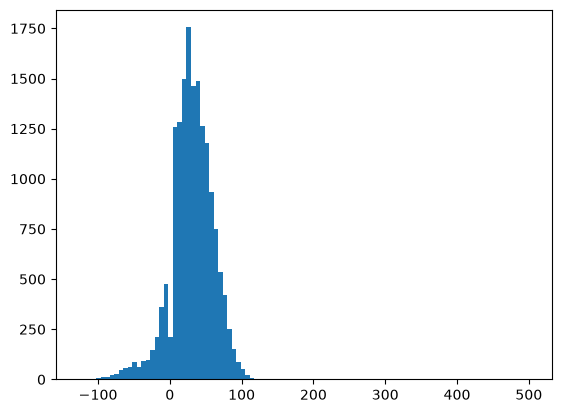

,payment_id,order_id,payment_type,amount,paid_at
14,P008386,O007403,charge,500.5,2026-05-01 20:52:51


In [1004]:
# Lets look for amount outliers

print(f"Missing amounts {payments["amount"].isna().sum()}")
!pip install matplotlib --quiet
import matplotlib.pyplot as plt
plt.hist(payments["amount"], bins=100)
plt.show()
# Som massive positive outliers
display(
    payments[
        payments["amount"] > 150
    ]
)
# Their is one at 500.5. This could be the case as somebody could have order a massive meal. 
# It is such an extreme outlier though so will skew the results and its only one so I am removing it.
payments = payments[
    payments["amount"] < 150
]




In [1005]:
# Now need to colate the order net payment
order_payments = payments.groupby("order_id").agg(
    net=("amount","sum"),
    num_transactions=("order_id","count")
).reset_index()
display(order_payments)
# Lets cross ref this

display(payments[
    payments["order_id"] == "O000005"
])
# It works

,order_id,net,num_transactions
0,O000001,37.49,1
1,O000002,31.99,1
2,O000003,12.50,1
3,O000004,46.99,1
4,O000005,0.00,2
...,...,...,...
14488,O014490,56.99,1
14489,O014491,22.49,1
14490,O014492,23.49,1
14491,O014493,43.99,1


,payment_id,order_id,payment_type,amount,paid_at
12664,P000005,O000005,charge,6.0,2026-03-01 11:33:58
15492,P000006,O000005,refund,-6.0,2026-03-01 11:43:21


In [1006]:
# Now lets join them
combined = orders.copy()
combined = combined.merge(order_payments, on="order_id", how="left")
# Lets check nothing got lost or added
print(f"Combined length {combined.shape[0]}; orders length {orders.shape[0]}")
# None added
print(f"Missing Payments {combined["net"].isna().sum()}")
# One is missing
display(
    combined[
        combined["net"].isna()
    ]
)
# No payments were made (lets assume that it just hasn't been paid for yet and drop it)
display(payments[
    payments["order_id"] == "O007403"
])
combined = combined.dropna(subset="net")
print(f"Missing Payments {combined["net"].isna().sum()}")




Combined length 14494; orders length 14494
Missing Payments 1


,order_id,customer_id,restaurant_id,order_ts,delivery_fee,week,net,num_transactions
7402,O007403,C03307,R047,2026-05-01 20:52:06+00:00,0.0,2026-04-27,NaN,NaN


,payment_id,order_id,payment_type,amount,paid_at


Missing Payments 0


In [1007]:
# Now lets add city and cuisine
combined = combined.merge(restaurants,on="restaurant_id",how="left")
# Nothing got add (drop was from combining with payments)
print(f"Combined length {combined.shape[0]}; orders length {orders.shape[0]}")
print(f"Missing cities {combined["city_clean"].isna().sum()}")
print(f"Missing cuisines {combined["cuisine_clean"].isna().sum()}")
# All worked great

# Now we can answer the question (not duration yet)
print(combined.groupby(["week", "city", "cuisine"]).agg(
        net_revenue=("net","sum"),
        order_count=("order_id", "count")
    ))


Combined length 14493; orders length 14494
Missing cities 0
Missing cuisines 0
                                net_revenue  order_count
week       city       cuisine                           
2026-02-23 Birmingham Burgers        125.99            4
                      Chinese        117.46            7
                      Indian          43.99            1
                      Italian         80.98            3
                      Italian         57.96            5
...                                     ...          ...
2026-06-29 Manchester Japanese       277.44            7
                      Mexican        366.05           15
                      Thai           475.46           15
                      mexican        242.42            8
                      thai            42.99            1

[714 rows x 2 columns]


## 4. Check

*Show how you know your answer is right. What did you compare, count or spot check, and what did the checks show? If a check failed, say what you changed.*

Add text here as you go along. Show that you are staying in control of the build!

## 5. Prompts and AI notes

*Paste each prompt you used, as you sent it. Then note what you accepted, what you changed or rejected, and why. Include at least one example where the AI was wrong or needed correcting, if that happened.*

Did not use AI used pre prepared cheat sheet. (see on my github box1273002)

## 6. What I could not verify

*Be honest about what remains unchecked, and what you would do next with more time.*

I was able to clean the payments orders and restaurants table. Join them would be the next step to get the final table. I also need to clean order updates for average delivery time.

## Self-check before you stop

Tick these off in your head or in a text cell. They mirror the three things the real test is marked on.

**How was the code generated?**
- [ ] Every block of code that matters has a prompt or a source associated with it.
- [ ] I can say what each block is meant to do and what output I expected.

**Evidence of checking**
- [ ] For every table I built, I checked the number of rows against what I expected, and I can say why.
- [ ] I checked that keys I treat as unique are unique, and I looked for duplicates.
- [ ] My final table agrees with the source data in at least one total, and I show the comparison.
- [ ] I looked at individual records, not only at totals.
- [ ] I wrote down at least one thing the checks caught, and what I changed (if possible).

**Interpretation in my own words**
- [ ] I state each decision (week, which orders count, net revenue, delivery time) and why I chose it.
- [ ] I say what the figures can and cannot be trusted for.
- [ ] Section 6 lists what I did not verify, honestly.